# Experimento 1 — As duas médias se complementam?

**Hipótese:** combinar as médias do usuário e do filme reduz o RMSE em relação a usar cada uma sozinha. Na EDA, ambas se associam à nota e têm baixa correlação entre si; isso motiva a comparação, mas não prova ganho adicional.

Comparamos constante e três regressões com intercepto: só usuário, só filme e ambas. Sem regularização ou busca de hiperparâmetros.

### O que este experimento traz de novo

| | |
|---|---|

| **Ponto de partida** | Previsão constante: sempre a média das notas do treino (RMSE ≈ 1,17). |
| **O que muda** | Primeira regressão linear do projeto, usando as médias do usuário ($u$) e do filme ($m$). |
| **Modelo** | Regressão linear por mínimos quadrados: $\hat y=b_0+b_u u+b_m m$. Os coeficientes minimizam a soma dos erros quadráticos no treino de cada dobra. |
| **Por que esta escolha** | É o modelo mais simples do curso que usa os atributos. Com três parâmetros, tem baixa variância e serve de referência para medir quanto cada mudança posterior acrescenta. As médias entram primeiro porque, na EDA, são os atributos mais associados à nota. |
| **Como ler o resultado** | Se as duas médias juntas superarem cada uma sozinha, elas trazem informação complementar. |

**Protocolo:** 5 dobras × 5 repetições, semente 2026; mesmas partições para os modelos, apenas `train.csv`, previsões cortadas em [0, 5].

O RMSE considera as cinco previsões fora da dobra (OOF) de cada linha separadamente. Só os gráficos usam a média dessas previsões. As partições compartilham treino: desvios e vitórias são descritivos, não testes de significância. As hipóteses vieram da exploração destes dados; não são confirmação independente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
df = pd.read_csv(ROOT / 'data' / 'train.csv')
FEATURES = ['user_avg_stars', 'movie_avg_stars']
y = df['stars'].to_numpy(dtype=float)
assert not df[FEATURES + ['stars']].isna().any().any()
assert 2 <= N_SPLITS <= len(df)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
print(f'{len(df)} observações; {N_SPLITS} folds × {N_REPEATS} repetições; semente {SEED}; corte: {CLIP}')

4000 observações; 5 folds × 5 repetições; semente 2026; corte: True


## 1. Relação entre médias e notas

As correlações e médias por faixas resumem associações; não isolam efeitos nem mostram toda a dispersão.

,user_avg_stars,movie_avg_stars,stars
user_avg_stars,1.000,0.002,0.455
movie_avg_stars,0.002,1.000,0.521
stars,0.455,0.521,1.000


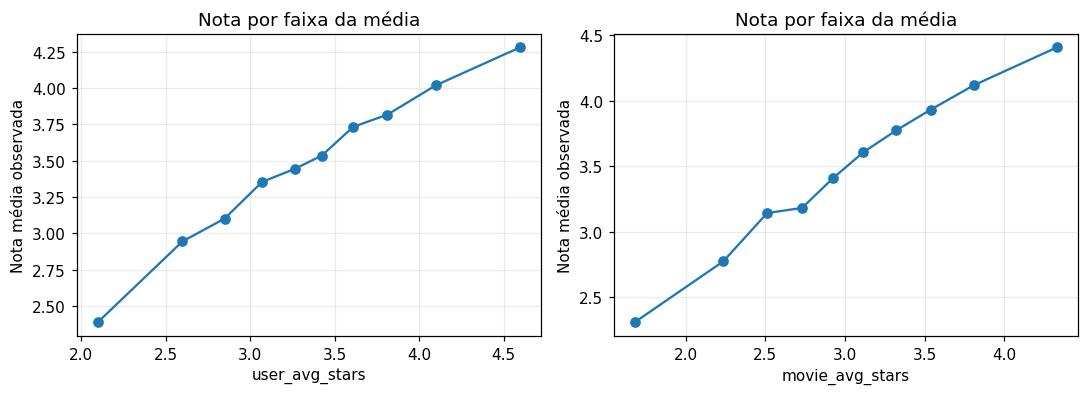

In [2]:
display(df[FEATURES + ['stars']].corr().round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for ax, feature in zip(axes, FEATURES):
    grouped = df.groupby(pd.qcut(df[feature], 10, duplicates='drop'), observed=True)
    table = grouped.agg(x=(feature, 'mean'), nota=('stars', 'mean'), n=('stars', 'size'))
    ax.plot(table['x'], table['nota'], 'o-')
    ax.set(xlabel=feature, ylabel='Nota média observada', title='Nota por faixa da média')
plt.tight_layout()
plt.show()

## 2. Comparar quatro modelos

Referências: constante, média do usuário e média do filme. Candidato: $\hat y=b_0+b_u u+b_m m$. Todos os coeficientes são estimados novamente no treino de cada dobra.

In [3]:
def rmse(actual, prediction):
    return float(np.sqrt(np.mean((actual - prediction) ** 2)))

candidates = {
    'Constante': [],
    'Só usuário': ['user_avg_stars'],
    'Só filme': ['movie_avg_stars'],
    'Duas médias': FEATURES,
}
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(df))
predictions_by_repeat = {name: np.full((N_REPEATS, len(df)), np.nan) for name in candidates}
rows = []
for name, columns in candidates.items():
    X = df[columns].to_numpy() if columns else np.zeros((len(df), 1))
    for fold, (train, valid) in enumerate(folds, start=1):
        model = LinearRegression() if columns else DummyRegressor(strategy='mean')
        model.fit(X[train], y[train])
        # Equação explícita evita avisos espúrios do matmul local.
        pred = (np.sum(X[valid] * model.coef_, axis=1) + model.intercept_
                if columns else model.predict(X[valid]))
        pred_train = (np.sum(X[train] * model.coef_, axis=1) + model.intercept_
                      if columns else model.predict(X[train]))
        # Verifique os valores antes do corte: ele poderia esconder infinitos.
        assert np.isfinite(pred).all() and np.isfinite(pred_train).all()
        if CLIP:
            pred = np.clip(pred, 0, 5)
            pred_train = np.clip(pred_train, 0, 5)
        predictions_by_repeat[name][(fold - 1) // N_SPLITS, valid] = pred
        rows.append({'modelo': name, 'fold': fold,
                     'E_CV': rmse(y[valid], pred),
                     'E_in': rmse(y[train], pred_train)})
assert all(np.isfinite(values).all() for values in predictions_by_repeat.values())
oof = pd.DataFrame({name: values.mean(axis=0) for name, values in predictions_by_repeat.items()})
by_fold = pd.DataFrame(rows)
summary = by_fold.groupby('modelo', sort=False).agg(
    E_CV=('E_CV', 'mean'),
    desvio_E_CV=('E_CV', 'std'),
    E_in=('E_in', 'mean'))
summary.insert(0, 'RMSE OOF repetido', [rmse(y, predictions_by_repeat[name]) for name in summary.index])
display(summary.round(4))

,RMSE OOF repetido,E_CV,desvio_E_CV,E_in
modelo,,,,
Constante,1.1659,1.1656,0.0255,1.1654
Só usuário,1.0384,1.0381,0.0279,1.0375
Só filme,0.9954,0.9951,0.0241,0.9947
Duas médias,0.8396,0.8394,0.0185,0.8385


## 3. Ganho das duas médias

Diferença = RMSE(duas médias) − RMSE(uma média). Valores negativos favorecem o modelo conjunto.

In [4]:
paired = by_fold.pivot(index='fold', columns='modelo', values='E_CV')
differences = pd.DataFrame({
    'Duas médias − só usuário': paired['Duas médias'] - paired['Só usuário'],
    'Duas médias − só filme': paired['Duas médias'] - paired['Só filme'],
})
display(differences.round(4))
for baseline in ['Só usuário', 'Só filme']:
    delta = differences[f'Duas médias − {baseline.lower()}']
    gain = summary.loc[baseline, 'RMSE OOF repetido'] - summary.loc['Duas médias', 'RMSE OOF repetido']
    print(f'Contra {baseline}: redução de RMSE OOF repetido = {gain:.4f}; '
          f'menor erro em {int((delta < 0).sum())}/{N_SPLITS * N_REPEATS} partições.')

if all(summary.loc['Duas médias', 'RMSE OOF repetido'] < summary.loc[b, 'RMSE OOF repetido']
       for b in ['Só usuário', 'Só filme']):
    print('Leitura: o resultado é compatível com contribuições complementares neste modelo e protocolo.')
else:
    print('Leitura: a comparação não sustentou ganho sobre ambos os modelos de uma média.')

,Duas médias − só usuário,Duas médias − só filme
fold,,
1,-0.1989,-0.1419
2,-0.2162,-0.1628
3,-0.1737,-0.1480
4,-0.1966,-0.1493
5,-0.2072,-0.1772
6,-0.1720,-0.1609
7,-0.2111,-0.1735
8,-0.1743,-0.1810
9,-0.2237,-0.1392


Contra Só usuário: redução de RMSE OOF repetido = 0.1989; menor erro em 25/25 partições.
Contra Só filme: redução de RMSE OOF repetido = 0.1558; menor erro em 25/25 partições.
Leitura: o resultado é compatível com contribuições complementares neste modelo e protocolo.


## 4. O que resta nos resíduos?

Resíduo = nota − previsão OOF. Valores positivos indicam subestimação. Procuramos padrões nas duas médias que possam motivar a próxima hipótese.

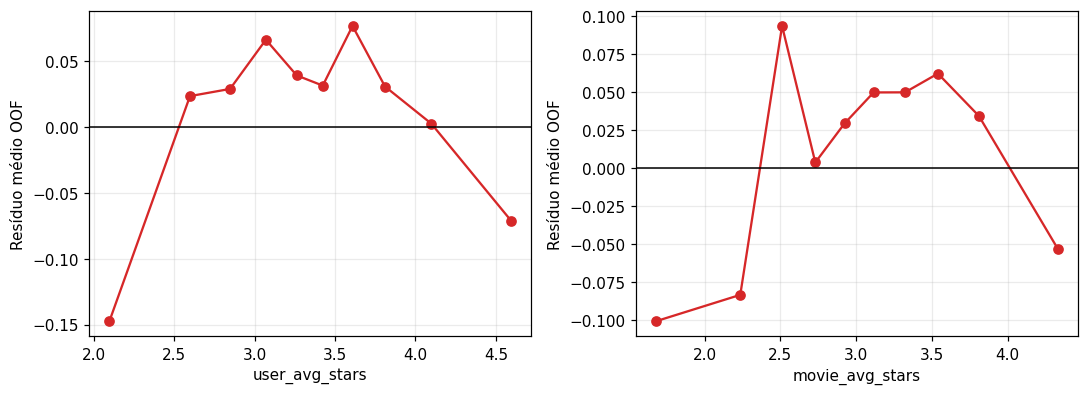

In [5]:
residual = y - oof['Duas médias'].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for ax, feature in zip(axes, FEATURES):
    diagnostic = df[[feature]].assign(residuo=residual)
    grouped = diagnostic.groupby(pd.qcut(diagnostic[feature], 10, duplicates='drop'), observed=True)
    table = grouped.agg(x=(feature, 'mean'), residuo=('residuo', 'mean'))
    ax.plot(table['x'], table['residuo'], 'o-', color='C3')
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel=feature, ylabel='Resíduo médio OOF')
plt.tight_layout()
plt.show()

## 5. Conclusão do grupo

- Juntar as médias trouxe ganho relevante em estrelas e consistente entre partições?
- Que padrões restaram nos resíduos?

**Respostas, com base na execução registrada abaixo.** Sim: o RMSE OOF caiu para 0,8396, contra 1,0384 (só usuário) e 0,9954 (só filme), com menor erro nas 25 partições nas duas comparações. Os resíduos ainda mostram padrões, que motivam a próxima hipótese.

A próxima hipótese testa a afinidade: a proporção do histórico correspondente ao gênero do filme. Nenhum modelo final é escolhido aqui.

## Registro reproduzível desta execução

Salvamos previsões OOF por repetição, erros por partição, configurações selecionadas, versões e identificadores dos dados e do código em `results/rodada_atual`. Esses arquivos não se misturam aos resultados históricos.

In [6]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.current_results import save_run
save_run(ROOT, '03_hipotese_duas_medias', df, y, predictions_by_repeat, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP, globals().get('selections'))

Resultados verificados e salvos em /Users/mrm/Documents/Disciplinas/Apredizagem Estatística/movie-rating-prediction/results/rodada_atual/03_hipotese_duas_medias.json


## Leitura da execução de 15 de novembro de 2026

Combinar as médias reduziu o RMSE OOF repetido para **0,839575**, contra **1,038440** usando só a média do usuário, **0,995403** usando só a média do filme e **1,165913** da constante. As duas informações se complementam nesta regressão. Isso motiva perguntar que estrutura os resíduos ainda carregam; o notebook 04 testa afinidade, mantendo as duas médias.

Esta leitura se refere à execução salva nesta rodada. Desvios e contagens são descritivos, não testes independentes. Revisar os números e o texto se dados, código ou configuração mudarem. As questões do grupo permanecem abertas à discussão.